# A keypoint detector trained on synthetic images

The chapter built a network that finds the eleven keypoints of Tango in an image, in two passes: a coarse one on the whole image that places a box around the target, and a fine one on the crop of that box. This notebook measures it. It follows the training, measures the error of the keypoints on synthetic images the network never saw, compares it with the requirement derived in the previous part, looks at where the large errors come from, and carries the keypoints through RANSAC to the pose, including the decision of which poses to trust.

The network was trained by `train.py` in this folder, on the synthetic training images fetched by `fetch_data.py`, on a laptop processor; the notebook only loads the result. As in the rest of the book no image of the dataset is shown, only quantities computed from them.

In [1]:
%matplotlib inline

from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

mpl.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.grid": True, "grid.alpha": 0.3, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
})

COL_A = "#1f77b4"
COL_B = "#d62728"
COL_C = "#9467bd"
COL_D = "#2ca02c"

# local copy of the dataset, filled on demand from the public archive
DATA = Path("../../data/speedplus")

import json
import time

from scipy.stats import chi2

from ios_pose_estimation.camera import project_pose
from ios_pose_estimation.crops import keypoint_box
from ios_pose_estimation.detector import INPUT_SIZE, KeypointDetector
from ios_pose_estimation.pnp import pose_errors, ransac_pnp, solve_pnp, speed_score
from ios_pose_estimation.rotations import quaternion_to_rotation_matrix
from ios_pose_estimation.speedplus import TANGO_EDGES, TANGO_KEYPOINTS, SpeedPlus

MODELS = Path("../../data/models")
dataset = SpeedPlus(DATA, remote=False)
camera = dataset.camera()
folder = DATA / "synthetic" / "images"
training = [label for label in dataset.labels("synthetic", "train") if (folder / label.filename).exists()]
validation = [label for label in dataset.labels("synthetic", "validation") if (folder / label.filename).exists()]
detector = KeypointDetector.load(MODELS / "detector.pt")
history = [json.loads(line) for line in open(MODELS / "detector_log.jsonl", encoding="utf-8")]

# a random fifth of the validation images calibrates the size of the errors, the rest measures them
order = np.random.default_rng(1).permutation(len(validation))
calibration = [validation[i] for i in np.sort(order[:300])]
held_out = [validation[i] for i in np.sort(order[300:])]
print(f"{len(training)} training images; {len(validation)} validation images, {len(calibration)} to calibrate "
      f"the errors and {len(held_out)} to measure them")

6875 training images; 1599 validation images, 300 to calibrate the errors and 1299 to measure them


## The training

After every epoch the training measured the median error of the keypoints on 500 validation images, with the true box (fine) and on the whole image (coarse), in pixels of the original image, and kept the weights of the best epoch.

20 epochs in 4.1 h of training; best epoch 17: fine median 3.82 px, 90th percentile 29.19 px, coarse median 11.0 px


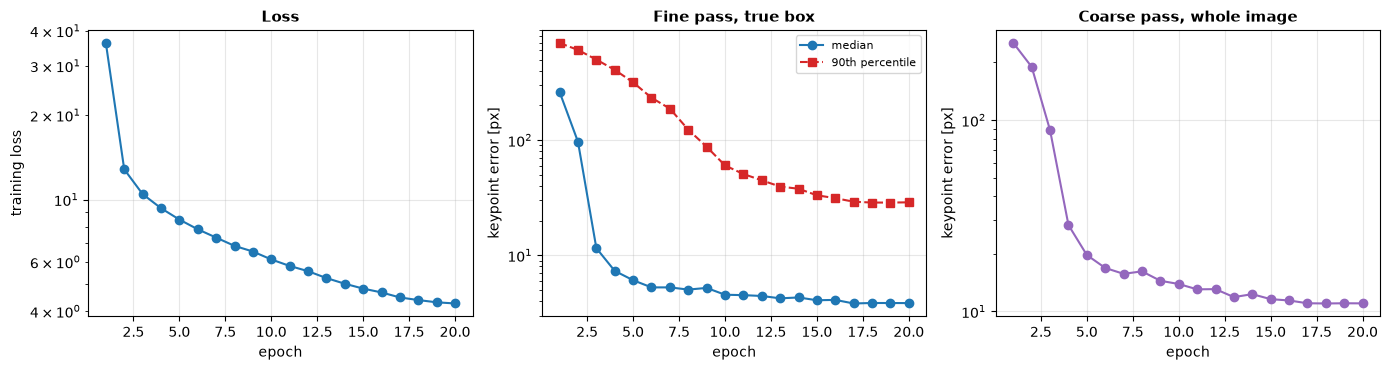

In [2]:
epochs = [h["epoch"] for h in history]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
axes[0].plot(epochs, [h["loss"] for h in history], "o-", color=COL_A)
axes[0].set_yscale("log"); axes[0].set_xlabel("epoch"); axes[0].set_ylabel("training loss"); axes[0].set_title("Loss")
axes[1].plot(epochs, [h["fine_median_px"] for h in history], "o-", color=COL_A, label="median")
axes[1].plot(epochs, [h["fine_p90_px"] for h in history], "s--", color=COL_B, label="90th percentile")
axes[1].set_yscale("log"); axes[1].set_xlabel("epoch"); axes[1].set_ylabel("keypoint error [px]")
axes[1].set_title("Fine pass, true box"); axes[1].legend(fontsize=8)
axes[2].plot(epochs, [h["coarse_median_px"] for h in history], "o-", color=COL_C)
axes[2].set_yscale("log"); axes[2].set_xlabel("epoch"); axes[2].set_ylabel("keypoint error [px]")
axes[2].set_title("Coarse pass, whole image")
fig.tight_layout()

best = min(history, key=lambda h: h["fine_median_px"])
hours = sum(h["seconds"] for h in history) / 3600
print(f"{len(history)} epochs in {hours:.1f} h of training; best epoch {best['epoch']}: fine median "
      f"{best['fine_median_px']:.2f} px, 90th percentile {best['fine_p90_px']:.2f} px, coarse median {best['coarse_median_px']:.1f} px")

Twenty epochs took about four hours on the processor of a laptop. The first epoch ended in the trap described in the chapter, a loss that falls while the keypoints stay hundreds of pixels off, and the network found its way out during the second and third; from there the median error fell steadily, to 3.8 px at epoch 17, and stopped improving, while the 90th percentile kept falling from hundreds of pixels to about 30. The two curves tell different stories from the start: most keypoints are found accurately early, and the long effort goes into the minority that are completely wrong.

The 500 images measured during training were the first 500 of the validation list, which is sorted by name, and in SPEED+ the first half of the names has a black background. The numbers of the log are therefore those of the easier images; the measurements below use a random sample of all of them. The training script now draws its validation images at random.

## Running the detector

Every validation image goes through the detector twice: once with the true box, which skips the coarse pass and measures the fine pass alone, and once as it would in operation, with the box found by the coarse pass. For each run the keypoints, the heights of their peaks and the side of the crop are kept, together with the depth of each keypoint behind the center of the target and the gray level of the background, the median of the image, which tells whether the Earth is behind the target. The error of a keypoint is measured both in pixels of the image and in pixels of the input of the network, the unit in which the chapter expects it not to depend on the distance.

In [3]:
def run(labels):
    rows = {"true": [], "depth": [], "background": [], "oracle": [], "oracle_side": [], "pixels": [], "conf": [],
            "side": [], "coarse": [], "seconds": []}
    for label in labels:
        image = dataset.image("synthetic", label.filename)
        truth, depth = project_pose(camera, label.quaternion, label.translation, TANGO_KEYPOINTS)
        oracle = detector.detect(image, box=keypoint_box(truth))
        started = time.perf_counter()
        found = detector.detect(image)
        rows["seconds"].append(time.perf_counter() - started)
        rows["true"].append(truth); rows["depth"].append(depth - label.translation[2])
        rows["background"].append(np.median(image))
        rows["oracle"].append(oracle.pixels); rows["oracle_side"].append(oracle.box[1])
        rows["pixels"].append(found.pixels); rows["conf"].append(found.confidence); rows["side"].append(found.box[1])
        rows["coarse"].append(found.coarse_pixels)
    return {key: np.array(value) for key, value in rows.items()}


calib = run(calibration)
test = run(held_out)
distance = np.array([label.distance for label in held_out])
earth = test["background"] > 20

def keypoint_errors(r, key="pixels", side="side"):
    image_px = np.linalg.norm(r[key] - r["true"], axis=2)
    return image_px, image_px * INPUT_SIZE / r[side][:, None]

oracle_img, oracle_in = keypoint_errors(test, "oracle", "oracle_side")
two_img, two_in = keypoint_errors(test)
coarse_img = np.linalg.norm(test["coarse"] - test["true"], axis=2)
print(f"two passes: {1e3 * np.median(test['seconds']):.0f} ms per image on this processor; "
      f"Earth in the background of {100 * earth.mean():.0f}% of the images")

two passes: 124 ms per image on this processor; Earth in the background of 37% of the images


## How accurate the keypoints are

The first comparison is between the fine pass with the true box and the whole detector, whose box comes from the coarse pass. A keypoint more than five pixels of the input away from the truth is counted as grossly wrong: at that distance it is not noise around the right point but a different point, the kind of error that RANSAC has to remove.

                         median      p90      p95    median     p95  > 5 px input
                           [px of the image]        [px of the input]
true box                   4.98    44.04   104.71      1.55   23.83         19.1%
coarse pass box            4.96    43.60   104.22      1.55   25.81         19.3%
coarse pass alone          15.8    172.7    282.0


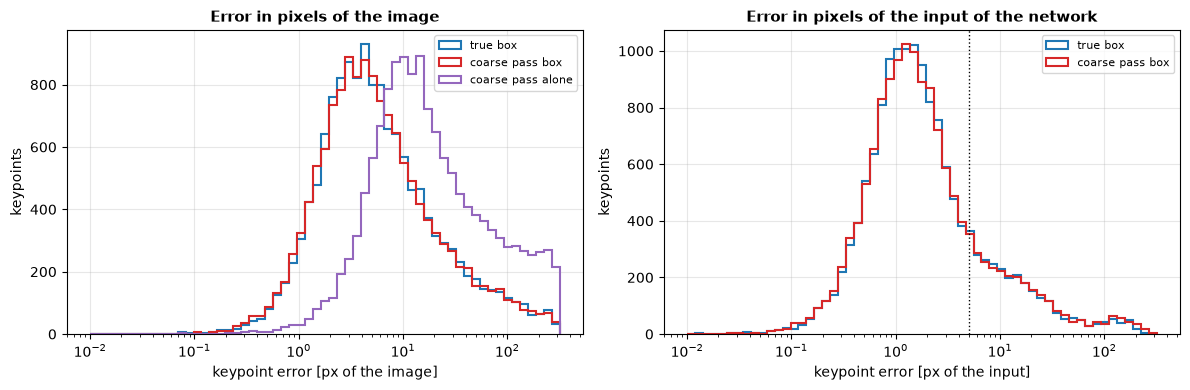

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
edges = np.logspace(-2, 2.5, 60)
for ax, (oracle, two, unit) in zip(axes, [(oracle_img, two_img, "image"), (oracle_in, two_in, "input")]):
    ax.hist(oracle.ravel(), bins=edges, histtype="step", lw=1.5, color=COL_A, label="true box")
    ax.hist(two.ravel(), bins=edges, histtype="step", lw=1.5, color=COL_B, label="coarse pass box")
    ax.set_xscale("log"); ax.set_xlabel(f"keypoint error [px of the {unit}]"); ax.set_ylabel("keypoints")
    ax.legend(fontsize=8)
axes[0].hist(coarse_img.ravel(), bins=edges, histtype="step", lw=1.5, color=COL_C, label="coarse pass alone")
axes[0].legend(fontsize=8); axes[0].set_title("Error in pixels of the image")
axes[1].axvline(5.0, color="k", lw=1, ls=":"); axes[1].set_title("Error in pixels of the input of the network")
fig.tight_layout()

print(f"{'':22s} {'median':>8s} {'p90':>8s} {'p95':>8s}   {'median':>7s} {'p95':>7s} {'> 5 px input':>13s}")
print(f"{'':22s} {'[px of the image]':^26s}   {'[px of the input]':^15s}")
for name, img, inp in [("true box", oracle_img, oracle_in), ("coarse pass box", two_img, two_in)]:
    print(f"{name:22s} {np.median(img):8.2f} {np.percentile(img, 90):8.2f} {np.percentile(img, 95):8.2f}   "
          f"{np.median(inp):7.2f} {np.percentile(inp, 95):7.2f} {100 * np.mean(inp > 5):12.1f}%")
print(f"{'coarse pass alone':22s} {np.median(coarse_img):8.1f} {np.percentile(coarse_img, 90):8.1f} {np.percentile(coarse_img, 95):8.1f}")

Half of the keypoints are found within 5 px of the image, 1.55 px of the input of the network; but almost one in five is grossly wrong, more than five pixels of the input away, which is where the 95th percentile of about a hundred pixels comes from. The coarse pass costs nothing: with its box the errors are the same as with the true one. On its own it is off by 16 px on median, which is of no use for the pose and plenty to place the crop. The two passes take about 120 ms per image on this processor.

## The Earth in the background

SPEED+ renders half of its synthetic images against black space and half with the Earth behind the target, and the two halves are separated by the names of the files: the images up to number 30,000 have a black background, those after it have the Earth in about three cases out of four. The table splits the errors of the keypoints by background.

In [5]:
gross = two_in > 5
print(f"{'background':>12s} {'images':>7s} {'median [px input]':>18s} {'grossly wrong':>14s}")
for name, chosen in [("black", ~earth), ("Earth", earth)]:
    print(f"{name:>12s} {chosen.sum():7d} {np.median(two_in[chosen]):18.2f} {100 * gross[chosen].mean():13.1f}%")

  background  images  median [px input]  grossly wrong
       black     824               1.36          18.2%
       Earth     475               1.91          21.3%


The Earth makes the keypoints less precise, 1.9 px of the input on median against 1.4, and makes gross errors only slightly more frequent, 21 percent against 18. The background is a difficulty, but not the main source of the gross errors, which are almost as frequent against black space.

## Against the requirement, distance by distance

The previous part found that the orientation stays within one degree in 95 percent of the cases if the keypoints are found within about 2 px at 10 m and 3 px at 5 to 7 m, which the chapter translated into about one pixel of the input at every distance. The left plot shows the median error in pixels of the image against the distance with that requirement; the right one the same error in pixels of the input, which the chapter predicts to be flat.

distance [m]  images  median [px image]  requirement  median [px input]  grossly wrong
         2.8     207              15.79         6.40               2.42          33.2%
         3.9     181               7.81         4.75               1.62          19.9%
         5.0     177               5.23         3.64               1.42          15.8%
         6.1     168               4.40         2.96               1.45          16.1%
         7.2     177               3.32         2.57               1.29          15.0%
         8.3     203               3.12         2.19               1.43          16.3%
         9.4     186               2.75         1.95               1.42          17.0%


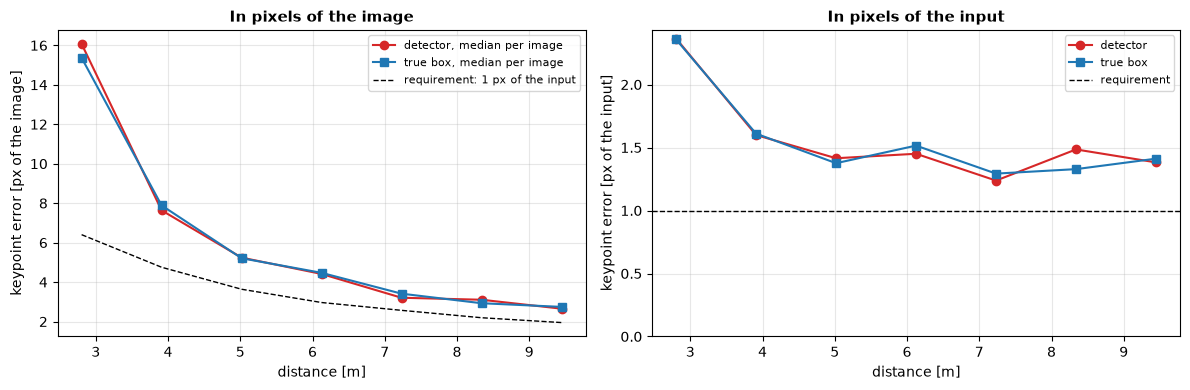

In [6]:
bins = np.linspace(2.25, 10.0, 8)
centers = 0.5 * (bins[1:] + bins[:-1])
index = np.digitize(distance, bins) - 1
def binned(values, q=50):
    return np.array([np.percentile(values[index == k], q) for k in range(len(centers))])

requirement = binned(test["side"], 50) / INPUT_SIZE          # one pixel of the input, in pixels of the image
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(centers, binned(np.median(two_img, axis=1)), "o-", color=COL_B, label="detector, median per image")
axes[0].plot(centers, binned(np.median(oracle_img, axis=1)), "s-", color=COL_A, label="true box, median per image")
axes[0].plot(centers, requirement, "k--", lw=1, label="requirement: 1 px of the input")
axes[0].set_xlabel("distance [m]"); axes[0].set_ylabel("keypoint error [px of the image]"); axes[0].legend(fontsize=8)
axes[0].set_title("In pixels of the image")
axes[1].plot(centers, binned(np.median(two_in, axis=1)), "o-", color=COL_B, label="detector")
axes[1].plot(centers, binned(np.median(oracle_in, axis=1)), "s-", color=COL_A, label="true box")
axes[1].axhline(1.0, color="k", lw=1, ls="--", label="requirement")
axes[1].set_ylim(bottom=0); axes[1].set_xlabel("distance [m]"); axes[1].set_ylabel("keypoint error [px of the input]")
axes[1].legend(fontsize=8); axes[1].set_title("In pixels of the input")
fig.tight_layout()

print(f"{'distance [m]':>12s} {'images':>7s} {'median [px image]':>18s} {'requirement':>12s} {'median [px input]':>18s} {'grossly wrong':>14s}")
for k, c in enumerate(centers):
    chosen = index == k
    print(f"{c:12.1f} {chosen.sum():7d} {np.median(two_img[chosen]):18.2f} {requirement[k]:12.2f} "
          f"{np.median(two_in[chosen]):18.2f} {100 * gross[chosen].mean():13.1f}%")

From 4 to 10 m the median error in pixels of the input is flat, between 1.3 and 1.5 px, as the chapter predicted: the crop makes the problem the same at every distance. It is flat at about 1.4 times the requirement, so in pixels of the image the curve runs parallel to the requirement and above it, 2.8 px against 2 at 9.4 m. Below 4 m it degrades, to 2.4 px and a third of the keypoints grossly wrong at 2.8 m. There the keypoints span almost the whole height of the image, the crop, 40 percent larger, extends beyond it, and in many images part of the target is simply not in the picture.

## Where the gross errors come from

Three explanations are tested. The first is that a keypoint that cannot be seen, because the body is between it and the camera, can only be guessed: the gross errors are split by the depth of the keypoint with respect to the center of the target, negative in front, positive behind. The second is confusion between keypoints: a wrong keypoint placed on the position of another one. Since eleven keypoints crowd a small box, a point placed at random also often falls near one of them, so the rate is compared with that of random points in the same box. The third is the near symmetry of Tango under a half turn about its $z$ axis, which takes the corners of the top panel onto one another and those of the bottom panel within 4 cm: a confusion of that kind would put the wrong keypoint on its partner under the turn. The last question is whether the network knows: the gross errors are compared across the heights of the peaks.

grossly wrong: 8.1% of the keypoints more than 10 cm in front of the center, 33.3% of those more than 10 cm behind it


2763 grossly wrong keypoints: 24% within 5% of the box from another keypoint, against 7% for a random point in the box; 3.1% on the half-turn partner
top 1      median  1.37 px, grossly wrong  22.2%
top 2      median  1.83 px, grossly wrong  17.9%
top 3      median  1.70 px, grossly wrong  15.5%
top 4      median  1.67 px, grossly wrong  17.9%
bottom 1   median  1.61 px, grossly wrong  21.3%
bottom 2   median  1.85 px, grossly wrong  22.7%
bottom 3   median  1.42 px, grossly wrong  19.9%
bottom 4   median  1.43 px, grossly wrong  22.6%
antenna 1  median  1.34 px, grossly wrong  18.5%
antenna 2  median  1.39 px, grossly wrong  16.5%
antenna 3  median  1.37 px, grossly wrong  17.9%
keypoints in the lowest tenth of confidence: 83% grossly wrong, against 12.2% for the others


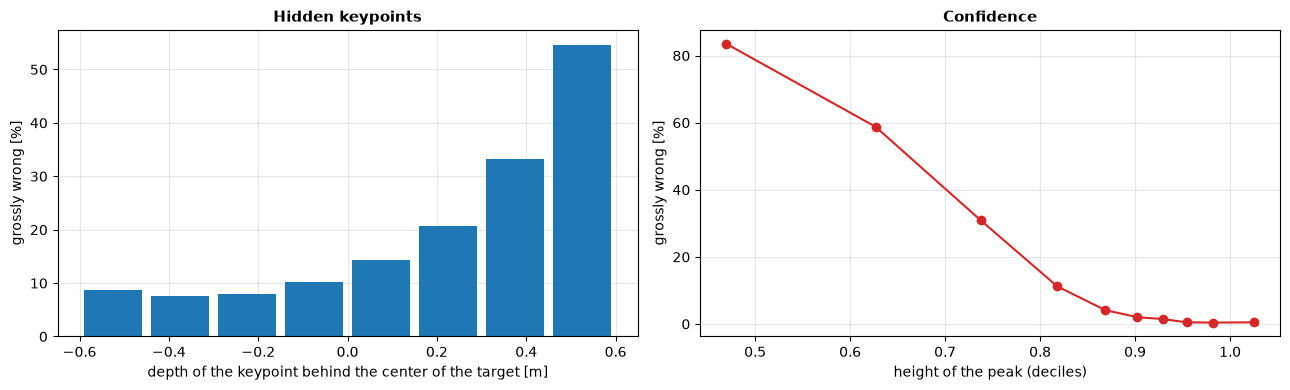

In [7]:
names = ["top 1", "top 2", "top 3", "top 4", "bottom 1", "bottom 2", "bottom 3", "bottom 4", "antenna 1", "antenna 2", "antenna 3"]
depth = test["depth"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
depth_bins = np.linspace(-0.6, 0.6, 9)
depth_index = np.clip(np.digitize(depth, depth_bins) - 1, 0, len(depth_bins) - 2)
axes[0].bar(0.5 * (depth_bins[1:] + depth_bins[:-1]), [100 * gross[depth_index == k].mean() for k in range(len(depth_bins) - 1)],
            width=0.13, color=COL_A)
axes[0].set_xlabel("depth of the keypoint behind the center of the target [m]"); axes[0].set_ylabel("grossly wrong [%]")
axes[0].set_title("Hidden keypoints")

conf = test["conf"].ravel(); err = two_in.ravel()
quantiles = np.quantile(conf, np.linspace(0, 1, 11))
groups = np.clip(np.digitize(conf, quantiles[1:-1]), 0, 9)
axes[1].plot([np.median(conf[groups == g]) for g in range(10)], [100 * np.mean(err[groups == g] > 5) for g in range(10)], "o-",
             color=COL_B)
axes[1].set_xlabel("height of the peak (deciles)"); axes[1].set_ylabel("grossly wrong [%]"); axes[1].set_title("Confidence")
fig.tight_layout()

front, back = depth < -0.1, depth > 0.1
print(f"grossly wrong: {100 * gross[front].mean():.1f}% of the keypoints more than 10 cm in front of the center, "
      f"{100 * gross[back].mean():.1f}% of those more than 10 cm behind it")

half_turn = np.diag([-1.0, -1.0, 1.0])
partner = np.array([np.argmin(np.linalg.norm(TANGO_KEYPOINTS - p, axis=1)) for p in TANGO_KEYPOINTS @ half_turn])
rng = np.random.default_rng(2)
landed = on_partner = chance = 0
for i, k in zip(*np.nonzero(gross)):
    center, side = keypoint_box(test["true"][i])
    others = np.delete(test["true"][i], k, axis=0)
    d = np.linalg.norm(test["true"][i] - test["pixels"][i, k], axis=1) / side
    d[k] = np.inf
    landed += d.min() < 0.05
    on_partner += d[partner[k]] < 0.05 and partner[k] != k
    random_point = center + side * rng.uniform(-0.5, 0.5, 2)
    chance += np.min(np.linalg.norm(others - random_point, axis=1)) / side < 0.05
total = gross.sum()
print(f"{total} grossly wrong keypoints: {100 * landed / total:.0f}% within 5% of the box from another keypoint, against "
      f"{100 * chance / total:.0f}% for a random point in the box; {100 * on_partner / total:.1f}% on the half-turn partner")

for k in range(11):
    print(f"{names[k]:10s} median {np.median(two_in[:, k]):5.2f} px, grossly wrong {100 * gross[:, k].mean():5.1f}%")
low = conf < np.quantile(conf, 0.1)
print(f"keypoints in the lowest tenth of confidence: {100 * np.mean(err[low] > 5):.0f}% grossly wrong, against "
      f"{100 * np.mean(err[~low] > 5):.1f}% for the others")

Visibility is the main cause. A keypoint more than 10 cm behind the center of the target, usually hidden by the body, is grossly wrong a third of the time; one more than 10 cm in front of it, 8 percent of the time. The network is asked to place hidden keypoints from the visible parts that imply them, and a third of the time it guesses wrong. Confusion between keypoints is real but secondary: a quarter of the wrong keypoints sit on another keypoint, against 7 percent for random points, and the half turn of the body explains only 3 percent of them, so the near symmetry of Tango is not what misleads the network. The errors are spread evenly over the eleven keypoints.

The network does know when it is unsure. Of the keypoints with the lowest tenth of peak heights, 83 percent are grossly wrong, against 12 percent of the others. Both findings point to the same improvement, a detector trained to say whether a keypoint is visible, rather than to guess every keypoint.

## From the keypoints to the pose

The keypoints of the detector now go through RANSAC and the refinement of the previous part, with an inlier threshold of 4 px of the input. The pixel error that the covariance needs is calibrated on the calibration images, as the robust standard deviation of the coordinate errors of the keypoints, in pixels of the input. For comparison, the same poses are also estimated from the true keypoints with a Gaussian error of that size added: the difference between the two is the part of the error that does not behave like noise.

calibrated pixel error: 1.37 px of the input per coordinate


                                     median      p95  < 1 deg  > 5 deg
detector + RANSAC                     1.176  115.033    42.3%    17.5%
  black background                    1.054  110.297    47.3%    15.8%
  Earth in the background             1.396  121.002    33.7%    20.4%
Gaussian error of the same size       0.664    1.519    80.1%     0.0%
normalized position error: median 0.0058, p95 0.7551
poses wrong by more than 150 deg: 3.4%; between 5 and 150 deg: 14.1%
SPEED+ score, mean over 1299 images: 0.3112 (median 0.0254)
NEES over all poses: median 8.8 against 5.3 expected


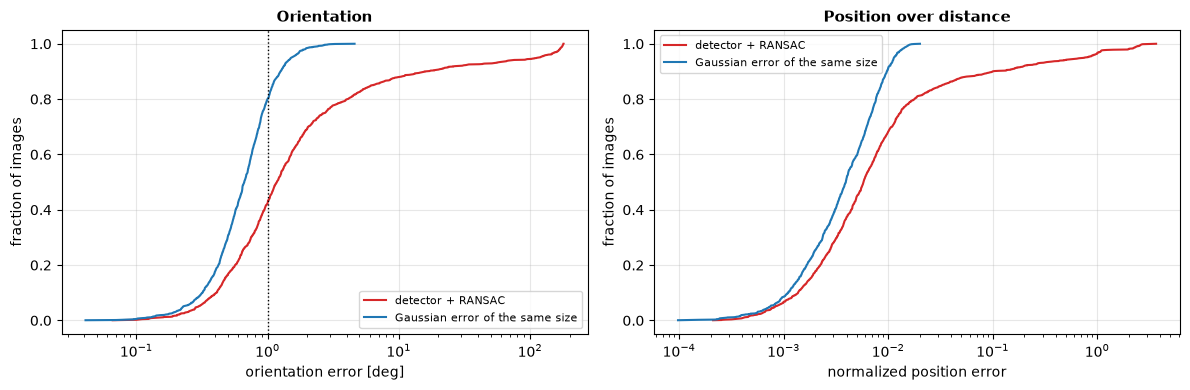

In [8]:
calib_in = (calib["pixels"] - calib["true"]) * INPUT_SIZE / calib["side"][:, None, None]
sigma_in = 1.4826 * np.median(np.abs(calib_in))
print(f"calibrated pixel error: {sigma_in:.2f} px of the input per coordinate")

rng = np.random.default_rng(0)
rows, gaussian, nees = [], [], []
for i, label in enumerate(held_out):
    scale = test["side"][i] / INPUT_SIZE
    estimate = ransac_pnp(camera, TANGO_KEYPOINTS, test["pixels"][i], threshold=4.0 * scale,
                          pixel_std=sigma_in * scale, rng=rng)
    orientation, _, position = pose_errors(estimate.quaternion, estimate.translation, label.quaternion, label.translation)
    score = speed_score(estimate.quaternion, estimate.translation, label.quaternion, label.translation)
    rows.append([np.degrees(orientation), position, score, estimate.inliers.sum(), estimate.rms_reprojection / scale])

    d = quaternion_to_rotation_matrix(estimate.quaternion).T @ quaternion_to_rotation_matrix(label.quaternion)
    small = 0.5 * np.array([d[2, 1] - d[1, 2], d[0, 2] - d[2, 0], d[1, 0] - d[0, 1]])
    e = np.concatenate([small, estimate.translation - label.translation])
    nees.append(e @ np.linalg.solve(estimate.covariance, e))

    noisy = test["true"][i] + sigma_in * scale * rng.standard_normal((11, 2))
    reference = solve_pnp(camera, TANGO_KEYPOINTS, noisy)
    o, _, p = pose_errors(reference.quaternion, reference.translation, label.quaternion, label.translation)
    gaussian.append([np.degrees(o), p])
rows, gaussian, nees = np.array(rows), np.array(gaussian), np.array(nees)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, column, name in [(axes[0], 0, "orientation error [deg]"), (axes[1], 1, "normalized position error")]:
    for values, colour, label in [(rows[:, column], COL_B, "detector + RANSAC"), (gaussian[:, column], COL_A, "Gaussian error of the same size")]:
        ordered = np.sort(values)
        ax.semilogx(ordered, np.arange(1, len(ordered) + 1) / len(ordered), color=colour, label=label)
    ax.set_xlabel(name); ax.set_ylabel("fraction of images"); ax.legend(fontsize=8)
axes[0].axvline(1.0, color="k", lw=1, ls=":")
axes[0].set_title("Orientation"); axes[1].set_title("Position over distance")
fig.tight_layout()

print(f"{'':34s} {'median':>8s} {'p95':>8s} {'< 1 deg':>8s} {'> 5 deg':>8s}")
for name, r in [("detector + RANSAC", rows), ("  black background", rows[~earth]), ("  Earth in the background", rows[earth]),
                ("Gaussian error of the same size", gaussian)]:
    print(f"{name:34s} {np.median(r[:, 0]):8.3f} {np.percentile(r[:, 0], 95):8.3f} {100 * np.mean(r[:, 0] < 1):7.1f}% {100 * np.mean(r[:, 0] > 5):7.1f}%")
print(f"normalized position error: median {np.median(rows[:, 1]):.4f}, p95 {np.percentile(rows[:, 1], 95):.4f}")
print(f"poses wrong by more than 150 deg: {100 * np.mean(rows[:, 0] > 150):.1f}%; between 5 and 150 deg: "
      f"{100 * np.mean((rows[:, 0] > 5) & (rows[:, 0] <= 150)):.1f}%")
print(f"SPEED+ score, mean over {len(rows)} images: {rows[:, 2].mean():.4f} (median {np.median(rows[:, 2]):.4f})")
print(f"NEES over all poses: median {np.median(nees):.1f} against {chi2.median(6):.1f} expected")

The median orientation error is 1.2 degrees, and 42 percent of the poses are within one degree. The tail is long: 17.5 percent of the poses are wrong by more than 5 degrees, and 3.4 percent by more than 150. The comparison with a Gaussian error of the same size, which gives a median of 0.66 degrees and no pose beyond 5, shows where the tail comes from. It is not the noise of the keypoints but the gross errors: with about two wrong keypoints per image on average, and often more when the hidden side faces the camera, RANSAC is sometimes outvoted. The Earth in the background raises the fraction of bad poses from 16 to 20 percent.

The position is known to 0.6 percent of the distance on median. The mean SPEED+ score, 0.31, is dominated by the failures, since a pose wrong by 180 degrees scores 3; the median score is 0.025. For the same reason the covariance is too small on average, with a median normalized error of 8.8 against 5.3.

## Telling a bad pose from a good one

A pose that is wrong by several degrees is worse than no pose, if the navigation believes it. Two quantities come with every pose for free: the number of keypoints RANSAC kept, and the residual of the kept keypoints in pixels of the input. The plot shows how the orientation error depends on them. The table tries simple rules that reject a pose when the residual is too large or too few keypoints were kept, and gives for each the fraction of bad poses caught, the fraction of all poses accepted, and the quality of the accepted ones, which is what the navigation would actually receive.

227 poses wrong by more than 5 deg (17.5%)
                              rule  bad caught  accepted  accepted: median  p95 [deg]  > 5 deg  NEES med
  residual > 3.0 px or inliers < 7         90%       77%              0.92       3.16     2.3%       6.5
  residual > 2.0 px or inliers < 8         97%       67%              0.85       2.61     0.7%       5.7
  residual > 2.0 px or inliers < 9         98%       57%              0.84       2.30     0.5%       5.5
  residual > 1.5 px or inliers < 9         99%       40%              0.73       1.88     0.4%       4.1


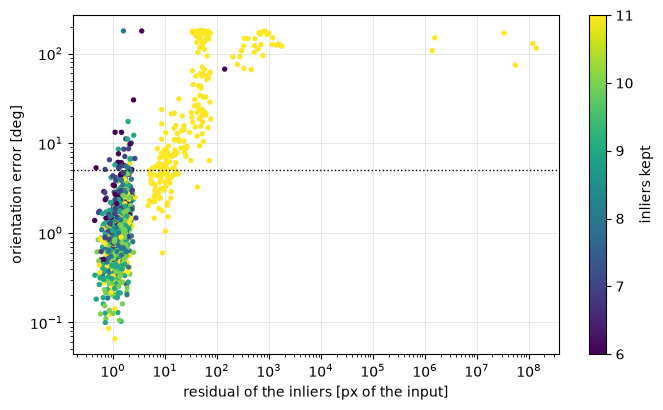

In [9]:
fig, ax = plt.subplots(figsize=(7, 4.2))
sc = ax.scatter(rows[:, 4], rows[:, 0], c=rows[:, 3], s=8, cmap="viridis", vmin=6, vmax=11)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("residual of the inliers [px of the input]")
ax.set_ylabel("orientation error [deg]"); fig.colorbar(sc, label="inliers kept")
ax.axhline(5.0, color="k", lw=1, ls=":")
fig.tight_layout()

bad = rows[:, 0] > 5.0
print(f"{bad.sum()} poses wrong by more than 5 deg ({100 * bad.mean():.1f}%)")
print(f"{'rule':>34s} {'bad caught':>11s} {'accepted':>9s} {'accepted: median':>17s} {'p95 [deg]':>10s} {'> 5 deg':>8s} {'NEES med':>9s}")
for residual_limit, inlier_limit in [(3.0, 7), (2.0, 8), (2.0, 9), (1.5, 9)]:
    flagged = (rows[:, 4] > residual_limit) | (rows[:, 3] < inlier_limit)
    kept = ~flagged
    print(f"{f'residual > {residual_limit} px or inliers < {inlier_limit}':>34s} {100 * flagged[bad].mean():10.0f}% "
          f"{100 * kept.mean():8.0f}% {np.median(rows[kept, 0]):17.2f} {np.percentile(rows[kept, 0], 95):10.2f} "
          f"{100 * bad[kept].mean():7.1f}% {np.median(nees[kept]):9.1f}")

The bad poses separate well. Rejecting a pose when the residual of its inliers exceeds 2 px of the input or when fewer than eight keypoints were kept catches 97 percent of the poses wrong by more than 5 degrees and accepts two poses out of three. The accepted ones have a median orientation error of 0.85 degrees and a 95th percentile of 2.6, only 0.7 percent of them are wrong by more than 5 degrees, and their covariance is consistent, with a median normalized error of 5.7 against 5.3. A stricter rule accepts 40 percent of the poses with a 95th percentile of 1.9 degrees.

This is the trade a sensor has to make, between availability and integrity. For a navigation filter that receives several images per second, losing one in three is acceptable; believing a pose wrong by tens of degrees is not.

## What the failures look like

The four worst poses, drawn without the image: the wireframe of Tango with the true pose, the keypoints found by the detector coloured by the height of their peak, and the wireframe with the estimated pose.

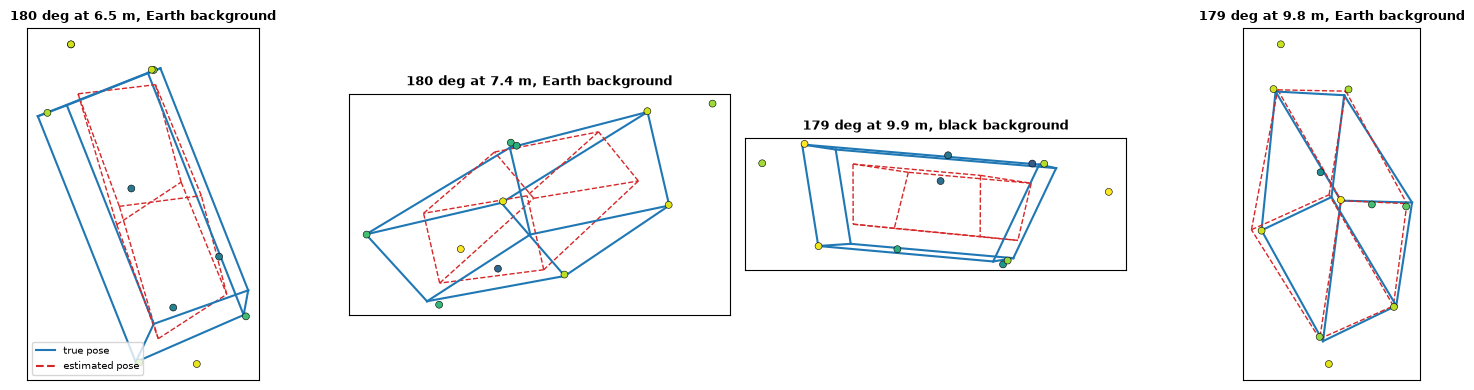

In [10]:
worst = np.argsort(rows[:, 0])[-4:][::-1]
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, i in zip(axes, worst):
    label = held_out[i]
    scale = test["side"][i] / INPUT_SIZE
    estimate = ransac_pnp(camera, TANGO_KEYPOINTS, test["pixels"][i], threshold=4.0 * scale, rng=np.random.default_rng(0))
    estimated, _ = project_pose(camera, estimate.quaternion, estimate.translation, TANGO_KEYPOINTS)
    truth = test["true"][i]
    for a, b in TANGO_EDGES:
        ax.plot(truth[[a, b], 0], truth[[a, b], 1], color=COL_A, lw=1.5)
        ax.plot(estimated[[a, b], 0], estimated[[a, b], 1], color=COL_B, lw=1, ls="--")
    ax.scatter(*test["pixels"][i].T, c=test["conf"][i], cmap="viridis", vmin=0, vmax=1, s=25, zorder=3,
               edgecolors="k", linewidths=0.4)
    ax.set_aspect("equal"); ax.invert_yaxis(); ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"{rows[i, 0]:.0f} deg at {label.distance:.1f} m, {'Earth' if earth[i] else 'black'} background",
                 fontsize=9)
axes[0].plot([], [], color=COL_A, label="true pose"); axes[0].plot([], [], color=COL_B, ls="--", label="estimated pose")
axes[0].legend(fontsize=7, loc="lower left")
fig.tight_layout()

The worst failures are all half turns, at 6.5 to 10 m. In each of them the estimated wireframe has almost the same outline as the true one: the target is turned by 180 degrees about an axis in the plane of the image, so that its front and back faces trade places, like the faces of a Necker cube. At these distances perspective is weak, the depth of the target is a small fraction of its distance, and the image of the turned body is nearly the same as that of the true one, especially when the hidden keypoints are guessed wrong. A single image can hardly tell them apart. A sequence can: a pose cannot turn by half a revolution between two images taken a fraction of a second apart, which is why a navigation filter that checks each pose against its prediction is the natural complement of this detector.

## Summary

A small heatmap network, trained in four hours on a laptop processor with 6,875 synthetic images, finds the keypoints of Tango with a median error of 1.4 px of the input from 4 to 10 m, flat in the distance as the chapter predicted, and 40 percent above the requirement of one pixel. One keypoint in five is grossly wrong, mostly keypoints hidden behind the body, and the network signals them with low peaks. Through RANSAC the orientation error has a median of 1.2 degrees and a long tail of failures, half turns among them.

With a simple rule on the residual and the number of inliers, the chain rejects 97 percent of the bad poses and delivers two poses out of three with a median error of 0.85 degrees, a 95th percentile of 2.6 and a consistent covariance. That is not yet the one degree at the 95th percentile of the requirement, and the measurements say what would close the gap: more training and resolution, which a graphics processor provides, a detector that predicts the visibility of each keypoint, and a filter that uses the continuity of a sequence. All of this is on synthetic images. The next part measures what is left on images of a real mock-up.